In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon

In [3]:
def gradient_polygon(ax, color, yst, yen):
    x0 = -1
    x1 = 1

    vertices = [
        [x0, yst],
        [x1, yst],
        [x1, yen],
        [x0, yen]
    ]

    polygon = Polygon(
        vertices,
        closed=True,
        facecolor='none',
        edgecolor='none'
    )
    ax.add_patch(polygon)

    cmap = LinearSegmentedColormap.from_list(
        'gradient',
        [color, 'white']
    )

    gradient = np.linspace(0.0001, 1, 500)[:, None]
    gradient = np.repeat(gradient, 500, axis=1)

    im = ax.imshow(
        gradient,
        extent=[x0, x1, yst, yen],
        origin='lower',
        aspect='auto',
        cmap=cmap,
        alpha=0.3
    )

    im.set_clip_path(polygon)

    return im

In [4]:
# the polar mean NH3 mixing ratio in kg/kg and the pressure in bar
with h5py.File('../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc', 'r') as h5file:
    sh_bg = np.array(h5file['vapor2'][0,:,0,0])
    pressure =np.array(h5file['press'][0,:,0,0]*1e-5)
    tb_bg = h5file['radiance'][0,:,0,0][::4]
    
print('pressure', pressure)
print('sh_bg', sh_bg.shape)

pressure [8.1030840e+03 8.0241284e+03 7.9459424e+03 ... 1.2978017e-03 1.2851562e-03
 1.2726338e-03]
sh_bg (1600,)


In [5]:
with h5py.File('/data/jihenghu/juno-mwr-deconv-research/16.yuanlian_simula/scaled_NH3_cpc.h5', 'r') as h5file:
    coret_NH3 = h5file['scaled_cpc_NH3'][:]
    coret30_NH3 = h5file['scaled30_cpc_NH3'][:]
    std1600 = h5file['scaled_cpc_NH3_std'][:]

std1600[pressure>20] = 0.0  ## set the std to zero for pressure > 10 bar




In [6]:
# clculate the cpc13457 mean NH3 mixing ratio in kg/kg and the pressure in bar

## grid / Tb anomaly used to define the CPC samples (same boxes as run_fit.ipynb)
with h5py.File("../observation/tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
    anomaly = h5f["anomaly"][:]
    lon2d = h5f["longitude"][:]
    lat2d = h5f["latitude"][:]
lon2d[lon2d > 180] -= 360

cpcs_lon_min = np.array([-30, -75, -130, -165, 145, 95, 60, 20])
cpcs_lon_max = np.array([10, -45, -90, -135, 180, 135, 90, 60])
cpcs_lat_min = np.array([80, 82, 80.5, 80.5, 81, 82.5, 79, 82.5])
cpcs_lat_max = np.array([85, 85, 85, 85, 85, 86, 83.5, 85.5])
thera = [1, 0.2, 1, 1, 0.35, 0.35, 1, 0.35]

## retrieved NH3 specific humidity [kg/kg] on the 1600 model levels
with h5py.File("../profiles_in_grid_dry.h5", "r") as h5f:
    shs_nh3 = h5f["shs_nh3"][:]
shs_nh3[shs_nh3 == 0] = np.nan       # unretrieved pixels

molefrac_bg = sh_bg                  # polar-mean background [kg/kg]

## per-CPC sample masks
cpc_masks = []
for i in range(8):
    lon_mask = (lon2d >= cpcs_lon_min[i]) & (lon2d <= cpcs_lon_max[i]) & (anomaly[5, :, :] > thera[i])
    lat_mask = (lat2d >= cpcs_lat_min[i]) & (lat2d <= cpcs_lat_max[i]) & (anomaly[5, :, :] > thera[i])
    cpc_masks.append(lon_mask & lat_mask)

def group_mean(cpcs):
    """pooled-sample mean/std of shs_nh3 over the member CPCs (1-based ids)"""
    mask = np.zeros_like(cpc_masks[0], dtype=bool)
    for cpc in cpcs:
        mask |= cpc_masks[cpc - 1]
    print(f"CPC {cpcs}: {np.count_nonzero(mask)} samples")
    return np.nanmean(shs_nh3[mask, :], axis=0), np.nanstd(shs_nh3[mask, :], axis=0)

shs, std = group_mean([1, 2, 3, 4, 5, 6, 7, 8])       
shs147, std147 = group_mean([1, 3, 4, 5, 7])   # strong-anomaly group
shs268, std268 = group_mean([2, 6, 8])

print('press', pressure.shape, 'shs', shs.shape)
print('at 2 bar:', 'bg=%.4e' % molefrac_bg[np.argmin(np.abs(pressure - 2))],
      'shs=%.4e' % shs[np.argmin(np.abs(pressure - 2))],
      'shs147=%.4e' % shs147[np.argmin(np.abs(pressure - 2))],
      'shs268=%.4e' % shs268[np.argmin(np.abs(pressure - 2))])

CPC [1, 2, 3, 4, 5, 6, 7, 8]: 675 samples
CPC [1, 3, 4, 5, 7]: 498 samples
CPC [2, 6, 8]: 177 samples
press (1600,) shs (1600,)
at 2 bar: bg=2.4632e-03 shs=2.3462e-03 shs147=2.3170e-03 shs268=2.4284e-03


In [7]:
# concat the shs147 at pressure<2 bar to the coret30_NH3 at pressure>2 bar
ind = pressure < 1.8
coret30_NH3[ind] = shs147[ind]


ind_12bar=np.argmin(np.abs(pressure - 12))
print('ind_12bar', ind_12bar, 'pressure[ind_12bar]', pressure[ind_12bar], 'coret30_NH3[ind_12bar]', coret30_NH3[ind_12bar])

ind_80bar=np.argmin(np.abs(pressure - 80))
print('ind_80bar', ind_80bar, 'pressure[ind_80bar]', pressure[ind_80bar], 'sh_bg[ind_80bar]', sh_bg[ind_80bar])

# damp the coret30_NH3 anomaly (relative to the polar mean) from 12 bar down to
# zero at 80 bar, so the deep profile merges smoothly back into sh_bg.
p_top, p_bot = pressure[ind_12bar], pressure[ind_80bar]

## anomaly carried at the top of the damping layer
d_top = coret30_NH3[ind_12bar] - sh_bg[ind_12bar]

## depth coordinate in log-pressure: 0 at 12 bar -> 1 at 80 bar (clipped outside)
tt = np.clip((np.log10(pressure) - np.log10(p_top)) /
             (np.log10(p_bot) - np.log10(p_top)), 0.0, 1.0)

## smootherstep taper: w=1 at 12 bar, w=0 at 80 bar, zero slope at both ends,
## so |dw/dlogp| grows first and then decays back to zero (S-shaped damping)
damp = 1.0 - (6*tt**5 - 15*tt**4 + 10*tt**3)

## --- logistic/tanh alternative (steeper mid-layer), renormalised to hit 1 and 0 exactly
# kk = 6.0
# raw = 0.5*(1.0 - np.tanh(kk*(tt - 0.5)))
# raw0, raw1 = 0.5*(1.0 - np.tanh(-kk/2)), 0.5*(1.0 - np.tanh(kk/2))
# damp = (raw - raw1) / (raw0 - raw1)

deep = pressure > p_top          # everything below 12 bar
coret30_NH3[deep] = sh_bg[deep] + d_top * damp[deep]

print('anomaly at 12 bar: %.4e' % d_top)
for pp in [12, 20, 30, 45, 60, 80, 120]:
    ii = np.argmin(np.abs(pressure - pp))
    print('  p=%7.2f bar  damp=%.3f  coret30=%.5e  bg=%.5e' %
          (pressure[ii], damp[ii], coret30_NH3[ii], sh_bg[ii]))


ind_12bar 665 pressure[ind_12bar] 12.043699 coret30_NH3[ind_12bar] 0.002646932
ind_80bar 472 pressure[ind_80bar] 79.70508 sh_bg[ind_80bar] 0.002553735
anomaly at 12 bar: 9.3197e-05
  p=  12.04 bar  damp=1.000  coret30=2.64693e-03  bg=2.55373e-03
  p=  20.04 bar  damp=0.875  coret30=2.63528e-03  bg=2.55373e-03
  p=  29.94 bar  damp=0.534  coret30=2.60350e-03  bg=2.55373e-03
  p=  45.17 bar  damp=0.164  coret30=2.56900e-03  bg=2.55373e-03
  p=  60.00 bar  damp=0.027  coret30=2.55623e-03  bg=2.55373e-03
  p=  79.71 bar  damp=0.000  coret30=2.55373e-03  bg=2.55373e-03
  p= 120.25 bar  damp=0.000  coret30=2.55373e-03  bg=2.55373e-03


In [8]:
with h5py.File('../juno_mwr_dipolar_scaled30-main.nc', 'r') as h5file:
    tb_cpc30 = h5file['radiance'][0,::4,0,0]

print("tb_cpc30", tb_cpc30)

tb_cpc30 [868.9985  482.34006 334.324   254.31009 196.6862  142.04842]


In [9]:
# cyclone 38N, tb anomaly spectra
xor=np.transpose([   [ 0.00205, 0.640],
    [0.00227, 1.24],
   [0.00244, 1.96],
   [ 0.00258, 2.86],
   [ 0.00267, 3.87],
   [ 0.00270, 4.28],
   [ 0.00275, 4.63],
   [ 0.00279, 5.42],
   [ 0.00282, 5.99],
   [ 0.00284, 6.93],
   [ 0.00284, 8.02],
   [ 0.00283, 9.80],
   [ 0.00283, 11.5],
   [ 0.00283, 13.9],
   [ 0.00282, 17.1],
   [ 0.00281, 20.5],
   [ 0.00280, 23.7],
   [ 0.00280, 27.7]])

In [10]:
# anticyclone GRS 18S
tbGRS =np.transpose([
    [-0.0142, 0.590],
    [-0.0193, 1.37],
    [-0.0131, 3.59],
    [-0.0147, 9.30],
    [0.00784, 27.8],
    [0.0266, 118]
])

tbGRSfit =np.transpose([
    [-0.0132, 0.590],
    [-0.0149, 1.37],
    [-0.0148, 3.59],
    [-0.0148, 9.30],
    [0.00784, 27.8],
    [0.0266, 118]
])


tbGRSerrx = [-0.0246,
        -0.0310,
        -0.0205,
        -0.0173, 
        0.00524, 
        0.0231]

tbGRSerry1=[ 0.497,
            0.700,
            1.77,
            3.8,
            9.37,
            22.5]

tbGRSerry2=[ 0.658,
            2.65,
            6.85,
            19.6,
            75.5,
            1.63e+3
]

indxxx [False False False ... False False False]
strong (4,)
tb_anomaly_grp (3, 6)
[-29.82571691  -3.15757796   0.62732739   2.78437576   3.7909621
   1.58118861]
[0.497, 0.7, 1.77, 3.8, 9.37, 22.5]
[0.658, 2.65, 6.85, 19.6, 75.5, 1630.0]
[  0.59   1.37   3.59   9.3   27.8  118.  ]


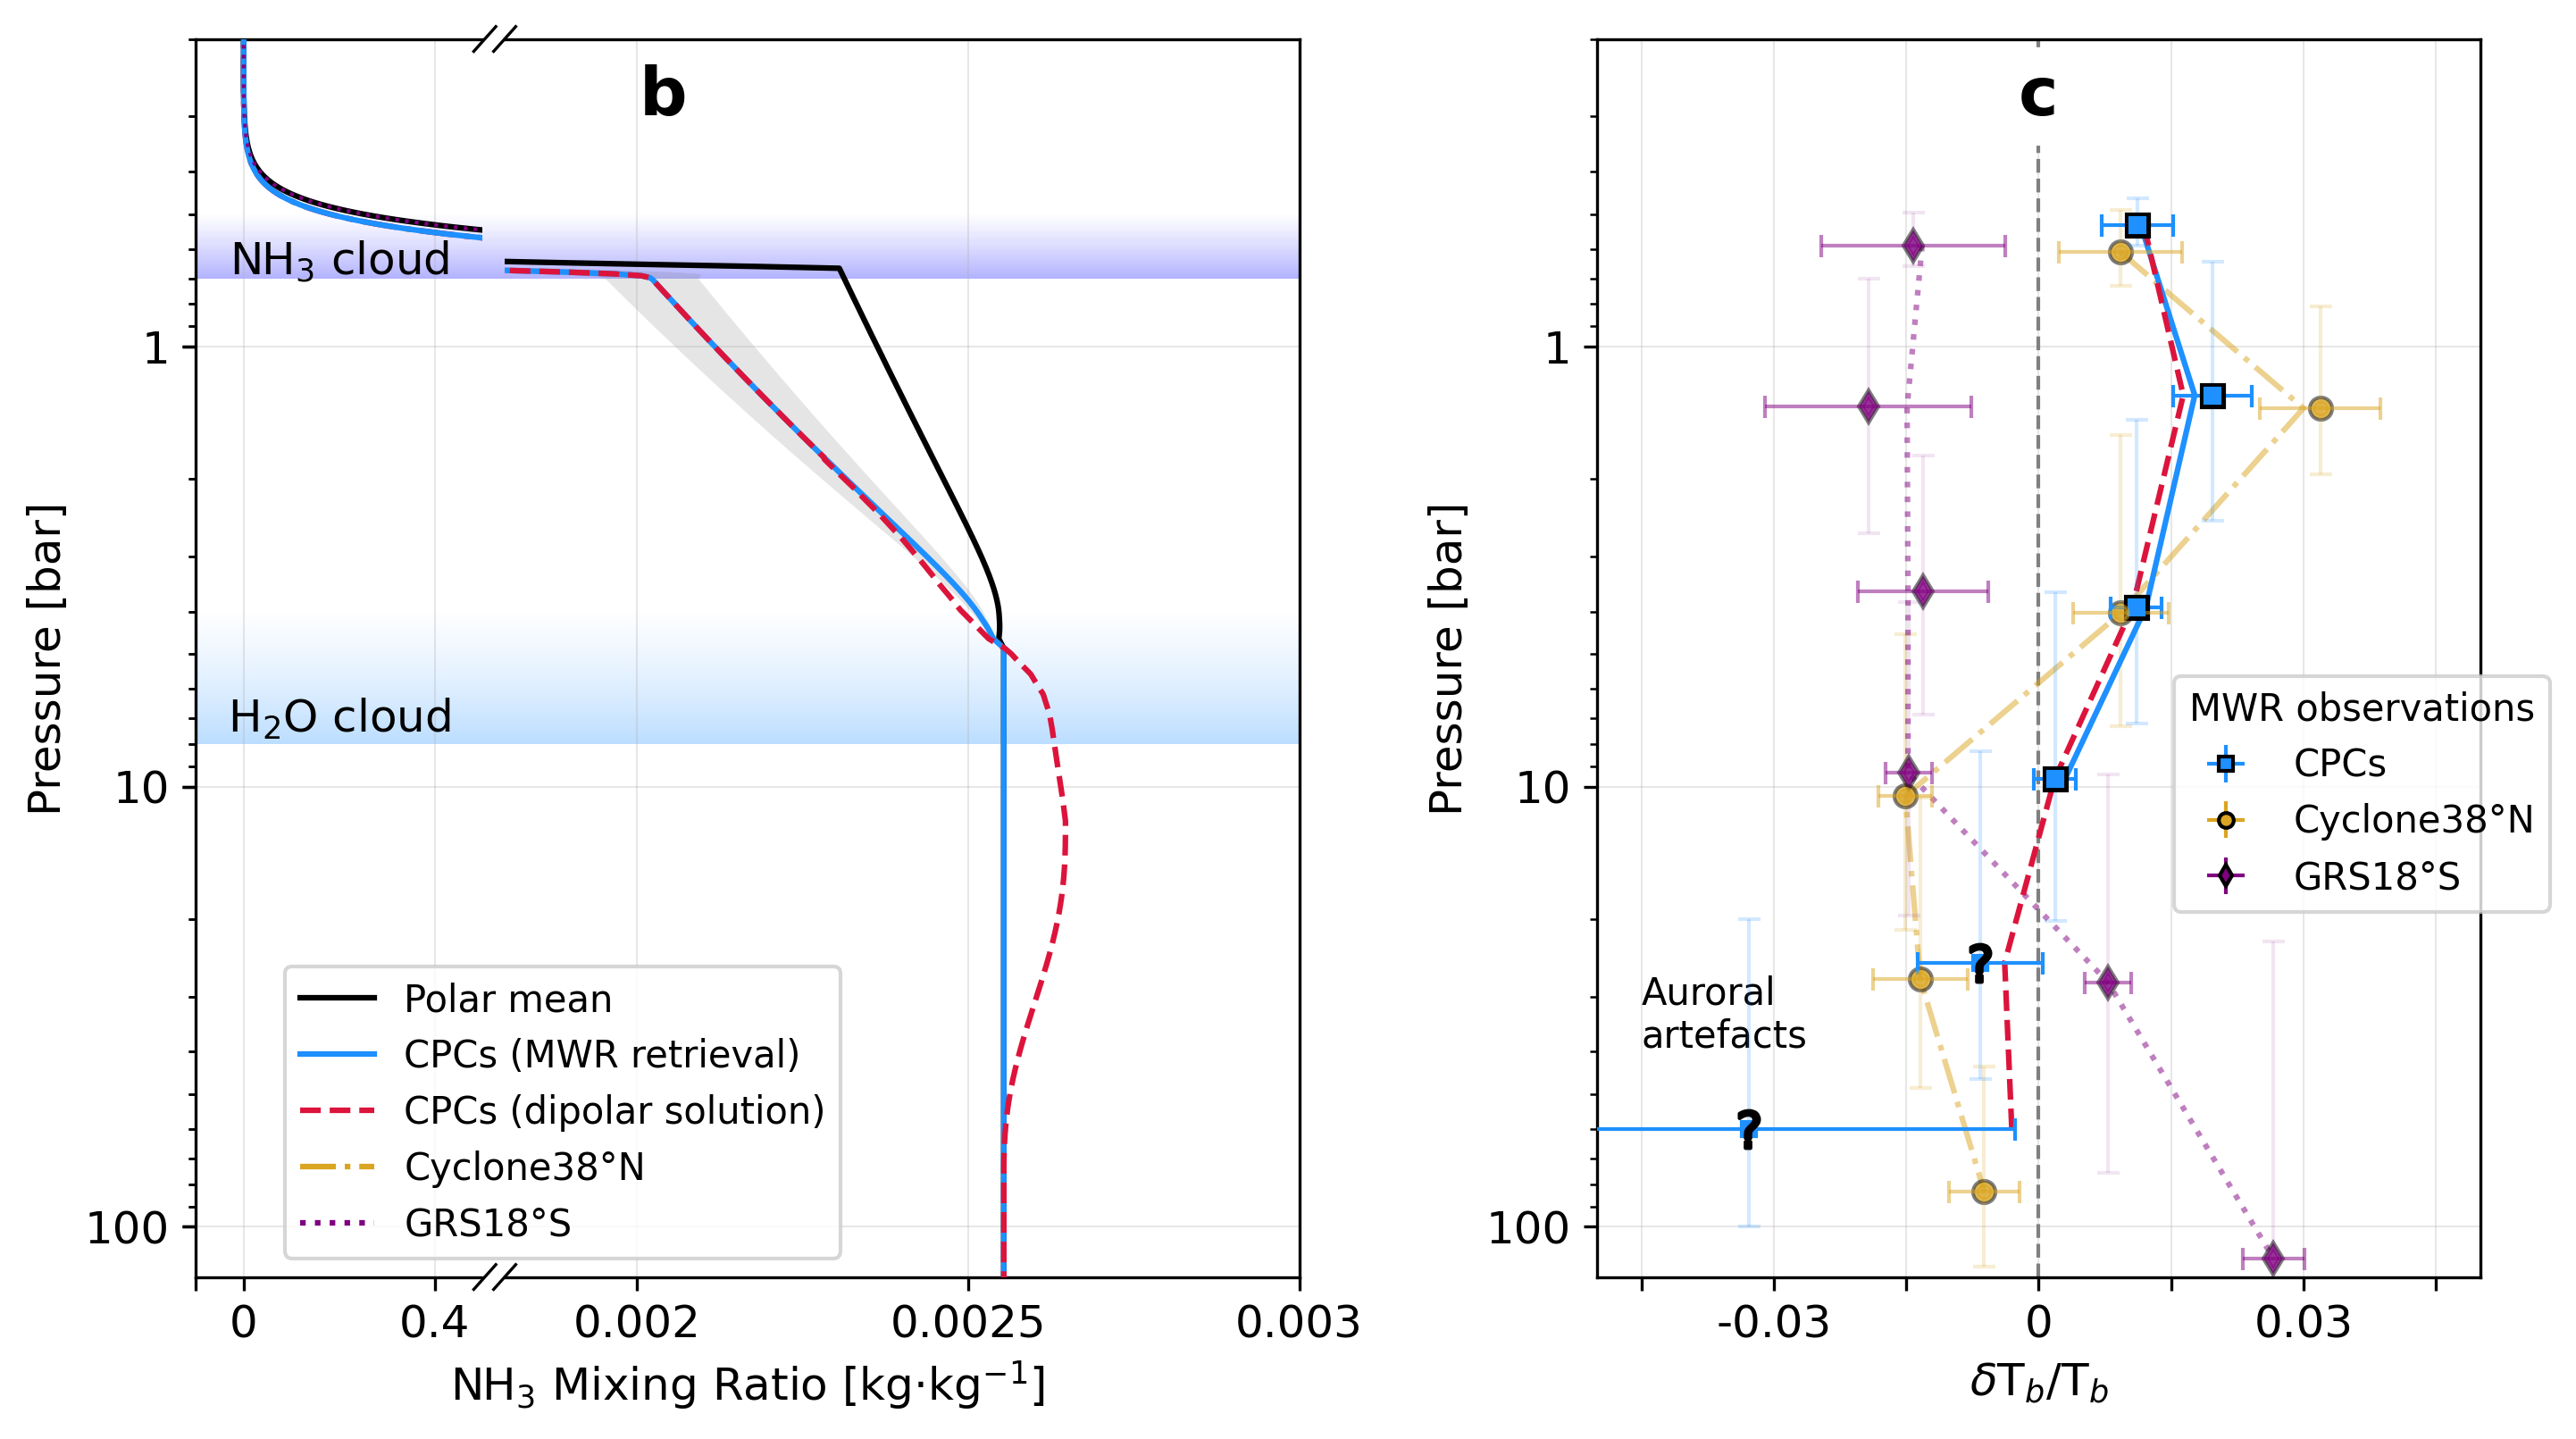

In [13]:
fig, [ax0, axb] = plt.subplots(1,2, figsize=(10*1.1,6*1), dpi=300, gridspec_kw={'width_ratios': [1,0.8]})
fig.subplots_adjust(wspace=0.3)

for spine in ax0.spines.values():
    spine.set_visible(False)
ax0.set_xticks([-1,100])
ax0.set_xticklabels(["",""])
ax0.set_yticks([])
ax0.set_ylim(130, .2)
ax0.set_yscale('log')
ax0.set_yticklabels([])
ax0.grid(linewidth=0.5, linestyle='-', alpha=0.3)
ax0.set_xlabel(r'NH$_3$ Mixing Ratio [kg$\cdot$kg$^{-1}$]', fontsize=12, labelpad=15)

ax0.plot((0.262+0.01, 0.262-0.01), (1+0.01, 1-0.01), transform=ax0.transAxes, linewidth=0.8, color='k', clip_on=False, zorder=40)
ax0.plot((0.28+0.01, 0.28-0.01), (1+0.01, 1-0.01), transform=ax0.transAxes, linewidth=0.8, color='k', clip_on=False, zorder=40)

ax0.plot((0.262+0.01, 0.262-0.01), (+0.01, -0.01), transform=ax0.transAxes, linewidth=0.8, color='k', clip_on=False, zorder=40)
ax0.plot((0.28+0.01, 0.28-0.01), (+0.01, -0.01), transform=ax0.transAxes, linewidth=0.8, color='k', clip_on=False, zorder=40)


ax=ax0.inset_axes([0.28,0,0.72,1], zorder=10)

# set ticks on only the right side of the left inset axes
ax.set_ylabel('')
ax.spines['left'].set_visible(False)
ax.set_yscale('log')
ax.set_ylim(130,.2)
ax.set_xlim(0.0018, 0.003)

ax.set_xticks([0.002,0.0025,0.003], labels=[0.002,0.0025,0.003], fontsize=12)
ax.set_yticklabels([])
ax.tick_params(axis='y', which='both', left=False)

# ax.tick_params(xlabelsize=12, ylabelsize=12)
# ax.invert_yaxis()
ax.grid(linewidth=0.5, linestyle='-', alpha=0.3)



# the polar mean profile
ax.plot(sh_bg, pressure, 'k-', linewidth=1.5, zorder=5, label='Polar mean')

ax.legend(fontsize=12, frameon=False, loc='upper right', bbox_to_anchor=(1.0, 1.0))
# ax.plot(shs, pressure, 'black', label='CPC mean')
ax.plot(shs147, pressure, 'dodgerblue', label='CPCs (MWR retrieval)', zorder=10)

# ax.plot(shs268, pressure, 'crimson', label='CPC #2,#6,#8')



indxxx= (pressure>10) & (coret30_NH3<molefrac_bg)
print("indxxx", indxxx)
coret30_NH3[indxxx]=molefrac_bg[indxxx]

ax.plot(coret30_NH3, pressure,  '--', color='crimson', label='CPCs (dipolar solution)', zorder=10)

# ax.fill_betweenx(pressure, shs-std, shs+std, color='gray', alpha=0.2, edgecolor='none')
ax.fill_betweenx(pressure, shs147-std147, shs147+std147, color='gray', alpha=0.2, edgecolor='none')

# ax.text(0.00255,1.3, 'Polar mean', color='k', fontsize=12, rotation=-59, va='center', ha='center', transform=ax.transData)

# ax.text(0.0023,2.2, r'Cyclone 38$^\circ$N', color='goldenrod', fontsize=12, rotation=-44, va='center', ha='center', transform=ax.transData)
ax.plot([],[], '-.', color='goldenrod', label='Cyclone38°N', zorder=10)
ax.plot([], [], ':', color='purple', label='GRS18°S', zorder=10)

#####################################################333333
ax_left=ax0.inset_axes([0,0,0.26,1])

ax_left.set_yscale('log')
ax_left.set_ylim(.2, 130)
ax_left.set_xlim(-0.0001, 0.0005)
ax_left.invert_yaxis()
ax_left.grid(linestyle='-', alpha=0.3, linewidth=0.5)
ax_left.spines['right'].set_visible(False)

ax_left.set_ylabel('Pressure [bar]', fontsize=12)
ax_left.set_xticks([0.,0.0004], labels=['0','0.4'], fontsize=12)
ax_left.set_yticks([1,10,100], labels=['1','10','100'], fontsize=12)

# plt.savefig('NH3_profile.png', dpi=300)
ax.text(0.2, 0.98, 'b', transform=ax.transAxes, fontsize=18, fontweight='bold', va='top', ha='center', zorder=30)

gradient_polygon(ax, 'dodgerblue', 8, 4)
gradient_polygon(ax_left, 'dodgerblue', 8, 4)
gradient_polygon(ax0, 'dodgerblue', 8, 4)

gradient_polygon(ax, 'b', 0.7, 0.5)
gradient_polygon(ax_left, 'b', 0.7, 0.5)
gradient_polygon(ax0, 'b', 0.7, 0.5)

ax_left.text(0.0002, 0.64, r'NH$_3$ cloud', transform=ax_left.transData, fontsize=12,  va='center', ha='center', zorder=20)
ax_left.text(0.0002, 7, r'H$_2$O cloud', transform=ax_left.transData, fontsize=12, va='center', ha='center', zorder=20)


ax_left.plot(sh_bg, pressure, 'k-', label='Polar mean', zorder=5)

# ax_left.plot(shs, pressure, 'k', label='Retrieved CPC mean')
ax_left.plot(shs147, pressure, 'dodgerblue', label='Linear depletion (retrieval)', zorder=10)
ax_left.plot(sh_bg, pressure, ':', color='purple', linewidth=1, zorder=10)
# ax_left.plot(shs268, pressure, 'crimson', label='CPC#2,#6,#8 mean')
ax_left.plot(coret30_NH3, pressure,  '-.', color='crimson', label='Dipolar anomaly')











#####################################################################333
# Spectra
#######################################################################
import h5py

# with h5py.File('juno_mwr_MPAS_scaled_cpc-main.nc', 'r') as h5file:
#     tb_cpc = h5file['radiance'][0,:,0,0][::4][2:]
# with h5py.File('juno_mwr_MPAS_scaled30_cpc-main.nc', 'r') as h5file:
#     tb_cpc30 = h5file['radiance'][0,:,0,0][::4][2:]


# tb_cpcs=tb_cpcs[[0,2,3,4,6]].mean(axis=0)
# std_pvs=std_pvs[[0,3,6]].mean(axis=0)

# tb_cpcs268=tb_cpcs[[1,5,7]].mean(axis=0)
# std_pvs=std_pvs[[0,3,6]].mean(axis=0)

outhdf=h5py.File("modelfit.h5", "r")
tb_anomaly_grp=outhdf["tb_anomaly"][:]
tb_anomaly_std_grp=outhdf["tb_anomaly_std"][:]
dry_mean_grp=outhdf["dry_mean"][:]
moist_mean_grp=outhdf["moist_mean"][:]


depth=[60, 25.10, 9.62, 3.91, 1.29, 0.53]


natb=[908.5,477.7,338.8,251.7,192.5,141.1]



strong=moist_mean_grp[0,:]
print("strong", strong.shape)
axb.plot(strong/natb[2:6], depth[2:6], '-', alpha=1, color='dodgerblue', zorder=10)
# axb.plot(tb_cpcs/tb_bg, depth[2:6], '--', alpha=1, color='k', label='CPC mean', zorder=10)





axb.plot(tb_cpc30/tb_bg-1, depth, '--',color='crimson',zorder=10)

yerr=[
    [[40],[40]],
    [[16.8],[21]],
    [[6], [10.6]],
    [[2.44], [3.26]],
    [[0.65], [1.2]],
    [[0.07], [0.06]],
]


print("tb_anomaly_grp", tb_anomaly_grp.shape)
print(tb_anomaly_grp[0,:])

# for ig in range(2):
for i in range(6):
  axb.errorbar(tb_anomaly_grp[0,i]/natb[i], depth[i], xerr=tb_anomaly_std_grp[0,i]/natb[i], fmt='s', color='dodgerblue',  capsize=3, elinewidth=1, markersize=4, zorder=10, alpha=1)
  axb.errorbar(tb_anomaly_grp[0,i]/natb[i], depth[i],  yerr=yerr[i], fmt='s', color='dodgerblue',  capsize=3, elinewidth=1, markersize=4,alpha=0.2, zorder=10)


for i in range(2, 6):
    axb.plot(tb_anomaly_grp[0,i]/natb[i], depth[i],'s', color='k', zorder=10)

for i in range(2):
    axb.scatter(tb_anomaly_grp[0,i]/natb[i], depth[i], marker='$?$ ', s=100, color='k', zorder=30)

# for i in range(6):
#   axb.errorbar(tb_anomaly_grp[1,i]/natb[i], depth[i], xerr=tb_anomaly_std_grp[1,i]/natb[i],  yerr=yerr[i], fmt='o', color='blue', alpha=0.5, capsize=3, elinewidth=1, markersize=4)





axb.set_xlabel(r'$\delta$T$_b$/T$_b$', fontsize=12)
axb.set_yscale('log')
axb.set_xlim(-.05, 0.05)
axb.set_xticks([-0.045,-0.03,-0.015, 0, 0.015, 0.03,0.045], labels=['','-0.03','','0','','0.03',''], fontsize=12)
axb.set_yticks([1,10,100], labels=['1','10','100'], fontsize=12)
axb.set_ylabel('Pressure [bar]', fontsize=12)
axb.set_ylim(130, 0.2)


axb.axvline(x=0, color='gray', linestyle='--', linewidth=1)
axb.grid(linewidth=0.5, linestyle='-', alpha=0.3)
axb.text(0.5, .98, 'c', transform=axb.transAxes, fontsize=18, fontweight='bold', va='top', ha='center', zorder=30, backgroundcolor='w')



# C38N
C38n = [0.00925, 0.0319, 0.00931, -0.0151, -0.0134, -0.00616], [0.6091, 1.38, 4.03, 10.5, 27.4, 83.2]


    # [[0.0007500, 0.6091  ],
    # [ 0.002450, 1.313  ],
    # [ 0.0007500, 4.057  ],
    # [ -0.001050, 10.74  ],
    # [ -0.0009500, 27.70  ],
    # [ -0.0004000, 83.32  ]]
C38n_retr = [0.00925, 0.03, 0.00931, -0.0151, -0.0134, -0.00616], [0.6091, 1.38, 4.03, 10.5, 27.4, 83.2]

axb.plot(C38n_retr[0], C38n_retr[1], '-.',color='goldenrod', alpha=0.5)
axb.plot(C38n[0], C38n[1], 'o',color='goldenrod', markeredgecolor='k', alpha=0.5)



yerr38n=[
    [[40],[40]],
    [[16.8],[21]],
    [[6], [10.6]],
    [[2.44], [3.26]],
    [[0.57], [0.57]],
    [[0.12], [0.12]],
][::-1]
axb.errorbar(C38n[0], C38n[1], xerr=[0.007, 0.0068,0.0054, 0.003, 0.0054, 0.004], fmt='o', color='goldenrod',  capsize=3, elinewidth=1, markersize=4, zorder=10, alpha=0.5)
for i in range(6):
    axb.errorbar(C38n[0][i], C38n[1][i], yerr=yerr38n[i], fmt='o', color='goldenrod', alpha=0.2, capsize=3, elinewidth=1, markersize=4)


# GRS

axb.plot(tbGRSfit[0], tbGRSfit[1], ':',color='purple', alpha=0.5)
axb.plot(tbGRS[0], tbGRS[1], 'd',color='purple', markeredgecolor='k', alpha=0.5)


print(tbGRSerry1)
print(tbGRSerry2)
print(tbGRS[1])


axb.errorbar(tbGRS[0], tbGRS[1], xerr=(tbGRS[0]-tbGRSerrx), fmt='d', color='purple', capsize=3, elinewidth=1, markersize=4, zorder=10, alpha=0.5)
for i in range(len(tbGRS[0])):
    ye1 = tbGRS[1][i]-tbGRSerry1[i]
    ye12 = tbGRSerry2[i]-tbGRS[1][i]
    axb.errorbar(tbGRS[0][i], tbGRS[1][i], yerr=[[ye1], [ye12]], fmt='d', color='purple', alpha=0.1, capsize=3, elinewidth=1, markersize=4)










axb.text(-0.045,33,'Auroral\nartefacts', fontsize=10, color='k', va='center', ha='left')





axb.errorbar([],[], xerr=[1],  yerr=[1], fmt='s', color='dodgerblue', markeredgecolor='k',  capsize=15, elinewidth=1, markersize=4, zorder=10, label='CPCs')
axb.errorbar([],[], xerr=[1],  yerr=[1], fmt='o', color='goldenrod', markeredgecolor='k',  capsize=15, elinewidth=1, markersize=4, zorder=10, label='Cyclone38°N')
axb.errorbar([],[], xerr=[1],  yerr=[1], fmt='d', color='purple', markeredgecolor='k',  capsize=15, elinewidth=1, markersize=4, zorder=10, label='GRS18°S')
# axb.errorbar([],[], xerr=[1],  yerr=[1], fmt='s', color='dodgerblue',  capsize=15, elinewidth=1, markersize=4, zorder=10, label='Auroal artefacts')
axb.legend(fontsize=10, frameon=True, loc='lower right', title='MWR observations', title_fontsize=10, bbox_to_anchor=(1.1, 0.28), facecolor='white')


ax.legend(fontsize=10, frameon=True, loc='lower left', bbox_to_anchor=(-0.3, 0.0))


fig.savefig('fig4.png', dpi=300, bbox_inches='tight', transparent=True)

In [10]:




# output the shs147, coret30_NH3, press1600 to h5 file
with h5py.File('NH3_profile_retrcpc147_scaled30.h5', 'w') as f:
    f.create_dataset('shs147', data=shs147)
    f.create_dataset('shs268', data=shs268)
    f.create_dataset('bgnh3', data=molefrac_bg)
    f.create_dataset('coret30', data=coret30_NH3)
    f.create_dataset('pressure', data=pressure)